# Panoramik Röntgenden Dental Yaş Tahmini: Ön Çalışma Düzeltmeleri ve Proje Analizleri

TÜBİTAK 2209-A ön çalışması, 2. kısım · Hazırlayan: Nurullah Barış Çelik · Danışman: Prof. Dr. Selami Beyhan

Bu notebook, 1. kısımdaki (dental_age_comparison.ipynb) karşılaştırmaya danışman tarafından önerilen düzeltmeleri uygular ve projenin iki ana katkısına ilişkin ilk analizleri içerir: belirsizliğin anatomik kaynağı ve adli öznitelik eklenmesi.

## 1. Deney protokolünde yapılan değişiklikler

| Ayar | 1. kısım | Bu çalışma | Gerekçe |
|---|---|---|---|
| Tekrar | 1 bölme, 1 başlangıç | 3 tekrarlı 5 katlı çapraz doğrulama (her tekrarda farklı bölme ve başlangıç) | Bölme ve başlangıç şansının etkisini ölçmek |
| Tur üst sınırı | 40 | 80 | ConvNeXt 1. katta 40 tur sınırına ulaşmıştı |
| Tur seçimi | Doğrulama hatası en düşük tek tur | Son 5 turun ortalama doğrulama hatası en düşük olan tur | 34 görüntülük doğrulama kümesinde tek tur seçimi gürültülü |
| Erken durdurma | 8 tur | Yumuşatılmış hata 12 tur iyileşmezse | Seçim kuralıyla uyumlu |
| Girdi | 224×224 (en boy oranı bozulur) | 224×224 ve ayrıca oranı koruyan 320×160 dolgulu girdi | Anizotropik bozulmanın etkisini ölçmek |

Her turda doğrulama ve test tahminleri kaydedilmiştir. Tur seçimi yalnızca doğrulama hatasıyla yapılır; kaydedilen test tahminleri, farklı seçim kurallarının sonradan karşılaştırılmasına olanak verir.

Beş modelden ConvNeXt-Tiny ve ConvNeXt türevleri Apple M2 üzerinde, diğer dört model ve simetri deneyi Google Colab T4 üzerinde eğitilmiştir. Ayarlar iki cihazda aynıdır.

In [1]:
import sys, json, re, warnings
sys.path.insert(0, 'scripts')
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import stats
import exp, analysis as A
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,
                     'grid.color':'#e6e5e1','grid.linewidth':.6,'axes.axisbelow':True,'font.size':10})
COLORS = {'ConvNeXt-Tiny':'#2a78d6','Xception':'#eb6834','DenseNet-121':'#1baf7a','EfficientNet-B0':'#eda100','ResNet-50':'#e87ba4'}
df = exp.load_df(); y = df.age.values.astype(float); bands = df.band.values
MODELS = {'ConvNeXt-Tiny':'convnext_square','ResNet-50':'resnet50_square','EfficientNet-B0':'efficientnet_square',
          'Xception':'xception_square','DenseNet-121':'densenet_square'}
RUNS = {}
for lab, name in list(MODELS.items()) + [('ConvNeXt dolgulu','convnext_pad'),('ConvNeXt + sıralama','convnext_rank'),
                                         ('ConvNeXt + simetri','convnext_sym'),('ConvNeXt + yirmilik evresi','convnext_feat')]:
    r = A.load_runs(name)
    if r: RUNS[lab] = A.add_val_ages(r, y)
print('Tamamlanan tekrar sayıları:', {k: len(v) for k,v in RUNS.items()})

Tamamlanan tekrar sayıları: {'ConvNeXt-Tiny': 3, 'ResNet-50': 3, 'EfficientNet-B0': 3, 'Xception': 3, 'DenseNet-121': 3, 'ConvNeXt dolgulu': 3, 'ConvNeXt + yirmilik evresi': 3}


## 2. Yakın yineleme eşiğinin sınanması

1. kısımda korelasyonu 0,90'ın üzerindeki görüntü çiftleri aynı gruba konmuştu. Panoramik görüntüler birbirine çok benzediğinden sıradan bir çiftin korelasyonu bile yaklaşık 0,70'tir. Aşağıda eşik taranmış ve her eşikte bulunan çiftlerin aynı yaşta olma oranı, rastgele çiftlerdeki oranla karşılaştırılmıştır. Aynı kişiye ait çiftler büyük olasılıkla aynı yaşta olacağından, bu oran eşiğin aynı kişiyi yakalayıp yakalamadığına dair dolaylı bir ölçüttür.

In [2]:
X = np.stack([np.asarray(Image.open(p).convert('L').resize((96,48), Image.BICUBIC), float).ravel() for p in df.path])
Z = (X - X.mean(1, keepdims=True)) / X.std(1, keepdims=True); C = Z @ Z.T / Z.shape[1]
iu = np.triu_indices(len(df), 1); c = C[iu]; da = np.abs(y[iu[0]] - y[iu[1]])
rows = []
for t in [.90, .88, .86, .85, .84, .82, .80]:
    m = c > t; par = list(range(len(df)))
    def f(x):
        while par[x] != x: par[x] = par[par[x]]; x = par[x]
        return x
    for i, j in zip(iu[0][m], iu[1][m]): par[f(i)] = f(j)
    roots = pd.Series([f(i) for i in range(len(df))])
    rows.append({'Eşik': t, 'Çift': int(m.sum()), 'Grup': roots.nunique(), 'En büyük grup': roots.value_counts().max(),
                 'Aynı yaş %': (da[m]==0).mean()*100 if m.any() else np.nan})
print(f'Rastgele çiftlerde aynı yaş oranı: %{(da==0).mean()*100:.1f} | tipik korelasyon (ortanca): {np.median(c):.3f}')
pd.DataFrame(rows).round({'Eşik': 2, 'Aynı yaş %': 1})

Rastgele çiftlerde aynı yaş oranı: %12.7 | tipik korelasyon (ortanca): 0.695


,Eşik,Çift,Grup,En büyük grup,Aynı yaş %
0,0.90,1,293,2,100.0
1,0.88,1,293,2,100.0
2,0.86,8,286,3,50.0
3,0.85,31,264,8,29.0
4,0.84,86,236,50,19.8
5,0.82,396,139,153,18.2
6,0.80,1232,78,212,18.8


Eşik 0,86'nın altına indikçe bulunan çift sayısı hızla artmakta, aynı yaşta olma oranı ise rastgele çiftlerin düzeyine yaklaşmaktadır. Bu nedenle piksel korelasyonu, aynı kişiye ait görüntüleri benzer çekim koşullarındaki farklı kişilerden ayıramamaktadır. Eşik 0,90 olarak bırakılmıştır; bu korumanın fiilen yalnızca bir çifti grupladığı ve veri setinde aynı hastanın birden fazla görüntüsü varsa sonuçların iyimser olabileceği sınırlılık olarak kabul edilmiştir.

## 3. Beş modelin tekrarlı karşılaştırması

Her model için üç tekrarın her birinde tüm görüntülerin kat dışı tahminleri elde edilmiş ve MAE hesaplanmıştır. Tabloda üç tekrarın ortalaması ve standart sapması, katlar arası standart sapmanın ortalaması ve üç tekrarın tahminlerinin ortalaması alınarak elde edilen topluluk MAE'si verilmiştir.

In [3]:
base = A.median_baseline(df, RUNS['ConvNeXt-Tiny']) if 'ConvNeXt-Tiny' in RUNS else None
tbl = []
for lab in MODELS:
    if lab not in RUNS: continue
    P = A.oof(RUNS[lab], len(df)); s = A.summarize(P, y, RUNS[lab]); m = A.metrics(y, P.mean(0))
    tbl.append({'Model': lab, 'Tekrar': s['reps'], 'MAE ort.': s['MAE_mean'], 'MAE std (tekrar)': s['MAE_sd'], 'Kat std': s['fold_sd'],
                'Topluluk MAE': s['MAE_ensemble'], 'R² (topluluk)': m['R2'], 'Eğim': m['slope'],
                'Ort. tur': s['epochs'], 'Seçilen tur': s['epoch_selected'], '80 tura ulaşan kat': s['hit_cap']})
res = pd.DataFrame(tbl).sort_values('MAE ort.').reset_index(drop=True)
if base is not None: print('Taban çizgisi (ortanca) MAE:', round(np.abs(base - y).mean(), 3))
res.round(3)

Taban çizgisi (ortanca) MAE: 2.041


,Model,Tekrar,MAE ort.,MAE std (tekrar),Kat std,Topluluk MAE,R² (topluluk),Eğim,Ort. tur,Seçilen tur,80 tura ulaşan kat
0,ConvNeXt-Tiny,3,0.991,0.016,0.081,0.951,0.741,0.721,41.733,30.000,1
1,ResNet-50,3,1.057,0.046,0.071,1.002,0.719,0.720,45.800,34.000,1
2,Xception,3,1.114,0.037,0.069,1.054,0.676,0.666,43.333,31.333,0
3,DenseNet-121,3,1.118,0.027,0.087,1.063,0.694,0.666,35.533,23.533,0
4,EfficientNet-B0,3,1.119,0.043,0.074,1.076,0.676,0.626,44.000,32.067,1


In [4]:
if len(res) >= 3:
    AE = pd.DataFrame({lab: np.abs(A.oof(RUNS[lab], len(df)) - y).mean(0) for lab in res.Model})
    fr = stats.friedmanchisquare(*[AE[c] for c in AE])
    print(f'Friedman (görüntü başına, üç tekrarın ortalama mutlak hatası): χ²={fr.statistic:.2f}, p={fr.pvalue:.4f}')
    gaps = res['MAE ort.'] - res['MAE ort.'].min()
    print('En iyi modele uzaklık (yıl):', dict(zip(res.Model, gaps.round(3))))
    print('Katlar arası std aralığı:', round(res['Kat std'].min(),3), '-', round(res['Kat std'].max(),3))
    ranks = pd.DataFrame({lab: [np.abs(p - y).mean() for p in A.oof(RUNS[lab], len(df))] for lab in res.Model}).rank(axis=1)
    ranks.index = [f'Tekrar {i+1}' for i in range(len(ranks))]
    print('Tekrar başına sıralama (1 = en düşük MAE):'); display(ranks.astype(int))

Friedman (görüntü başına, üç tekrarın ortalama mutlak hatası): χ²=24.17, p=0.0001
En iyi modele uzaklık (yıl): {'ConvNeXt-Tiny': 0.0, 'ResNet-50': 0.065, 'Xception': 0.123, 'DenseNet-121': 0.127, 'EfficientNet-B0': 0.128}
Katlar arası std aralığı: 0.069 - 0.087
Tekrar başına sıralama (1 = en düşük MAE):


,ConvNeXt-Tiny,ResNet-50,Xception,DenseNet-121,EfficientNet-B0
Tekrar 1,1,2,3,5,4
Tekrar 2,1,3,4,2,5
Tekrar 3,1,2,4,5,3


Yorum için iki karşılaştırma önemlidir. Birincisi, modeller arasındaki MAE farkı ile katlar arası standart sapmanın büyüklüğüdür: farklar oynamayla aynı mertebedeyse, veri bölmesinin değişmesi sonucu model değişikliği kadar etkilemektedir. İkincisi, sıralamanın tekrarlar arasında korunup korunmadığıdır.

Pediatrik karşılaştırma yayınında ConvNeXt'i Xception ve DenseNet-121 izlemekteydi; 1. kısımda bu iki model son iki sırada yer almıştı. İki bağımsız çalışmada orta sıraların yer değiştirmesi, bu büyüklükteki veri setlerinde orta sıralamanın veri setine özgü gürültü olduğunu desteklemektedir.

## 4. Tur seçim kuralının etkisi

Aynı eğitimlerden üç kural karşılaştırılmıştır: son 5 turun ortalaması (ana kural), tek en iyi doğrulama turu (1. kısımdaki kural) ve eğitimin son turu.

In [5]:
rows = []
for lab in RUNS:
    row = {'Model': lab}
    for rule, nm in [('smooth','Son 5 tur ort.'),('best','Tek en iyi tur'),('last','Son tur')]:
        row[nm] = np.mean([np.abs(p - y).mean() for p in A.oof(RUNS[lab], len(df), rule)])
    gap = [np.abs(np.array(r['test_preds'][r['epoch_best']]) - y[r['te']]).mean() - r['hist'][r['epoch_best']]['val_mae'] for f in RUNS[lab].values() for r in f]
    row['Test − doğrulama farkı (tek en iyi tur)'] = np.mean(gap)
    rows.append(row)
pd.DataFrame(rows).round(3)

,Model,Son 5 tur ort.,Tek en iyi tur,Son tur,Test − doğrulama farkı (tek en iyi tur)
0,ConvNeXt-Tiny,0.991,1.013,0.974,0.111
1,ResNet-50,1.057,1.030,1.043,0.102
2,EfficientNet-B0,1.119,1.129,1.125,0.146
3,Xception,1.114,1.101,1.114,0.147
4,DenseNet-121,1.118,1.140,1.133,0.156
5,ConvNeXt dolgulu,0.976,0.996,0.969,0.098
6,ConvNeXt + yirmilik evresi,0.999,1.008,0.988,0.113


## 5. En boy oranını koruyan girdi

Görüntülerin çoğu 400×187 pikseldir. 224×224'e doğrudan boyutlandırma, yatay ekseni yaklaşık 0,56, dikey ekseni yaklaşık 1,20 katına getirerek dişleri olduğundan dar ve uzun gösterir. Karşılaştırmada oranı koruyan girdi aynı piksel bütçesiyle (320×160, yaklaşık 51 bin piksel) oluşturulmuş, kalan alan siyahla doldurulmuştur.

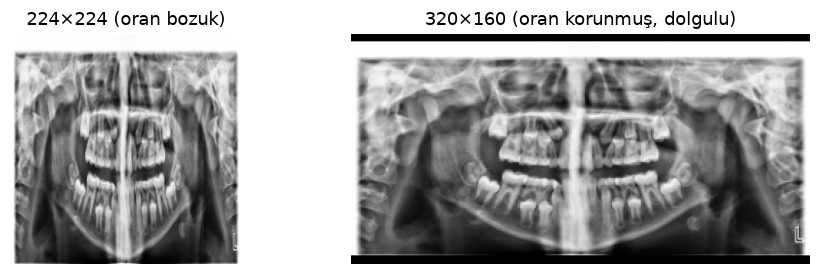

,Girdi,MAE ort.,MAE std,Topluluk MAE,9-11 MAE,12-13 MAE,14-15 MAE,16 MAE,17 MAE,18-19 MAE
0,ConvNeXt-Tiny,0.991,0.016,0.951,1.124,0.859,1.008,0.893,0.773,1.416
1,ConvNeXt dolgulu,0.976,0.041,0.935,1.086,0.882,0.961,0.904,0.771,1.369


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(9, 2.6))
p0 = df.path[0]
ax[0].imshow(exp.load_image(p0, 'square')[0], cmap='gray'); ax[0].set_title('224×224 (oran bozuk)')
ax[1].imshow(exp.load_image(p0, 'pad')[0], cmap='gray'); ax[1].set_title('320×160 (oran korunmuş, dolgulu)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()
rows = []
for lab in ['ConvNeXt-Tiny', 'ConvNeXt dolgulu']:
    if lab in RUNS:
        P = A.oof(RUNS[lab], len(df)); s = A.summarize(P, y, RUNS[lab])
        rows.append({'Girdi': lab, 'MAE ort.': s['MAE_mean'], 'MAE std': s['MAE_sd'], 'Topluluk MAE': s['MAE_ensemble'],
                     **{f'{b} MAE': v for b, v in A.band_mae(P, y, bands).items()}})
pd.DataFrame(rows).round(3)

## 6. 18-19 yaş bandındaki hatanın ayrıştırılması

1. kısımda en büyük hata 18-19 yaş bandında çıkmıştı. Bunun iki olası açıklaması vardır: görüntüdeki yaş sinyalinin tükenmesi ya da modelin tahminleri ortalamaya doğru çekmesi. En büyük on hatanın altısı yüksek yaşlarda düşük, dördü düşük yaşlarda yüksek tahmindir; bu, çekmenin beklenen imzasıdır.

İkisini ayırmak için her katta, yalnızca o katın doğrulama kümesinde tahmin = a × gerçek yaş + b doğrusu uydurulmuş ve test tahminleri (tahmin − b) / a ile düzeltilmiştir. Test verisi bu uydurmada kullanılmamıştır. Düzeltme sonrası bant hatası belirgin düşerse fazlalık çekmeden, düşmezse sinyal tükenmesinden kaynaklanmaktadır. Doğrulama kümeleri 34 görüntü olduğundan doğrunun kendisi de gürültülüdür.

In [7]:
if 'ConvNeXt-Tiny' in RUNS:
    R = RUNS['ConvNeXt-Tiny']
    P0 = A.oof(R, len(df)); P1 = A.oof(R, len(df), calibrate=True)
    slopes = [np.polyfit(np.array(r['va_age']), np.array(r['val_preds'][r['epoch_smooth']]), 1)[0] for f in R.values() for r in f]
    bt = pd.DataFrame({'n': pd.Series(bands).value_counts().reindex(A.BANDS).values,
                       'Ham MAE': A.band_mae(P0, y, bands).values, 'Kalibre MAE': A.band_mae(P1, y, bands).values,
                       'Ham yanlılık': pd.Series((P0 - y).mean(0)).groupby(bands, observed=True).mean().reindex(A.BANDS).values,
                       'Kalibre yanlılık': pd.Series((P1 - y).mean(0)).groupby(bands, observed=True).mean().reindex(A.BANDS).values},
                      index=A.BANDS)
    print(f'Doğrulama kümesinde uydurulan eğim: ortanca {np.median(slopes):.2f} (aralık {min(slopes):.2f}-{max(slopes):.2f})')
    print(f'Genel MAE: ham {np.abs(P0 - y).mean():.3f} | kalibre {np.abs(P1 - y).mean():.3f}')
    display(bt.round(2))

Doğrulama kümesinde uydurulan eğim: ortanca 0.74 (aralık 0.69-0.90)
Genel MAE: ham 0.991 | kalibre 1.150


,n,Ham MAE,Kalibre MAE,Ham yanlılık,Kalibre yanlılık
9-11,25,1.12,0.97,1.08,0.05
12-13,54,0.86,1.36,0.33,-0.36
14-15,62,1.01,1.27,0.53,0.62
16,50,0.89,1.30,-0.03,0.44
17,56,0.77,0.95,-0.51,0.13
18-19,47,1.42,0.92,-1.41,-0.68


## 7. Etiket kuantizasyonunun katkısı

Yaşlar tam yıl olarak verildiğinden, gerçek yaşın yıl içinde düzgün dağıldığı varsayımıyla etiketin kendisi standart sapması 1/√12 ≈ 0,289 yıl olan bir hata taşır. Bu değer kusursuz bir modelin MAE'sinden (0,25 yıl) farklı bir niceliktir ve gözlenen MAE'den doğrudan çıkarılamaz: bağımsız hata kaynakları varyansta toplanır.

In [8]:
if 'ConvNeXt-Tiny' in RUNS:
    rmse = A.metrics(y, A.oof(RUNS['ConvNeXt-Tiny'], len(df))[0])['RMSE']; q = 1/np.sqrt(12)
    print(f'Gözlenen RMSE (1. tekrar): {rmse:.3f} | kuantizasyonsuz RMSE: √({rmse:.3f}² − {q:.3f}²) = {np.sqrt(rmse**2 - q**2):.3f}')
    print(f'Kuantizasyonun MSE içindeki payı: %{q**2/rmse**2*100:.1f} | RMSE\'de yol açtığı artış: %{(rmse/np.sqrt(rmse**2-q**2)-1)*100:.1f}')

Gözlenen RMSE (1. tekrar): 1.317 | kuantizasyonsuz RMSE: √(1.317² − 0.289²) = 1.285
Kuantizasyonun MSE içindeki payı: %4.8 | RMSE'de yol açtığı artış: %2.5


Etiket kuantizasyonu toplam hatanın küçük bir kısmını açıklamaktadır ve bu düzeyde maddi bir hata kaynağı değildir.

## 8. Ortancaya yakın yaşta büyük düşük tahmin alan iki görüntü

16 yaş veri setinin ortancası olduğundan, ortalamaya çekme bu yaştaki görüntüleri büyük ölçüde düşük tahmin ettiremez. 1. kısımda 16 42.jpg ve 16 12.jpg yaklaşık 3,5 yıl düşük tahmin edilmişti. Aşağıda bu iki görüntü, aynı yaştan rastgele iki görüntüyle birlikte gösterilmiştir.

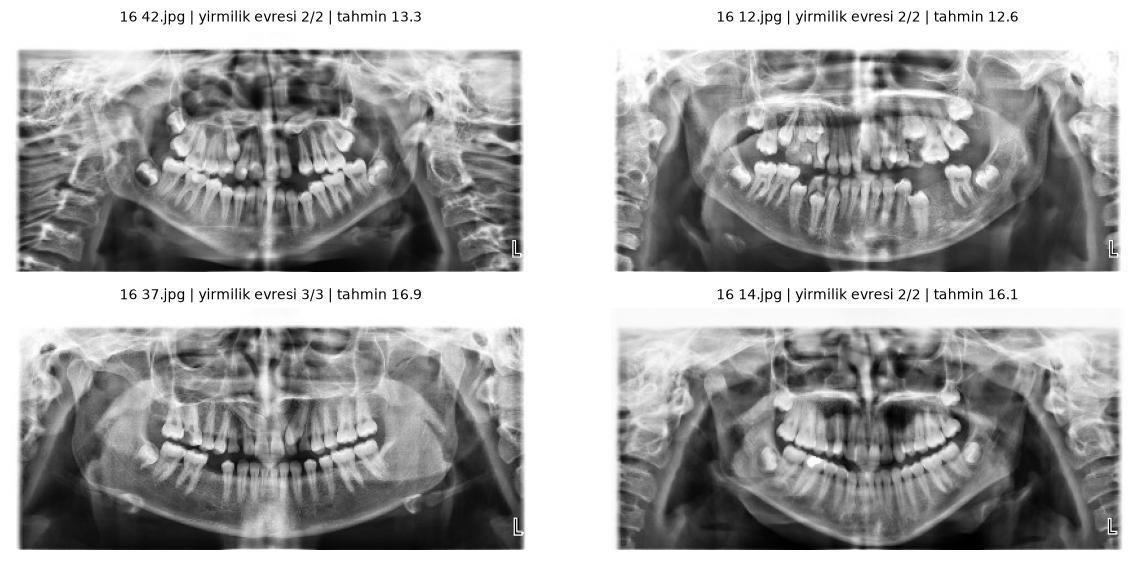

In [9]:
stages = pd.read_csv('annot/third_molar_stages.csv').set_index('name')
show = ['16 42.jpg', '16 12.jpg'] + list(df[(df.age==16) & ~df.name.isin(['16 42.jpg','16 12.jpg'])].sample(2, random_state=0).name)
P = A.oof(RUNS['ConvNeXt-Tiny'], len(df)) if 'ConvNeXt-Tiny' in RUNS else None
fig, axes = plt.subplots(2, 2, figsize=(11, 5.2))
for ax, n in zip(axes.ravel(), show):
    i = int(np.where(df.name == n)[0][0]); im = Image.open(df.path[i]).convert('L')
    t = f'{n} | yirmilik evresi {stages.loc[n, "s48"]:.0f}/{stages.loc[n, "s38"]:.0f}'
    if P is not None: t += f' | tahmin {P[:, i].mean():.1f}'
    ax.imshow(im, cmap='gray'); ax.set_title(t, fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

## 9. Ölçüm ve kapsam notları

Süre: 1. kısımdaki görüntü başına tahmin süresi, toplu boyut 1 ile Apple MPS üzerinde ölçülmüştü ve modelin gerçek verimini değil, çekirdek başlatma yükünü yansıtmaktadır. Bu nedenle bu sütun karşılaştırma tablosundan çıkarılmıştır. Eğitim süreleri yalnızca bilgi amaçlıdır.

Çözünürlük: 296 görüntünün 287'si 400 piksel genişliğindedir; özgün panoramikler 2041×1024 piksel mertebesindedir. Bu veride çözünürlük ablasyonu anlamlı biçimde yapılamaz ve projenin UFPE verisine bağlı iş paketine bırakılmıştır.

## 10. Belirsizlik kestirimi

Her görüntü, onu eğitimde görmemiş üç modelle (üç tekrarın ilgili katları) tahmin edilmiştir ve her modelde sekiz test zamanı çoğaltması uygulanmıştır (yatay ve dikey kaydırma, ölçek, parlaklık). Bu yapıdan iki belirsizlik ölçüsü elde edilir:

- Model belirsizliği: üç modelin ortalama tahminleri arasındaki standart sapma. Farklı veriyle ve başlangıçla eğitilen modellerin ne kadar anlaşamadığını gösterir.
- Çoğaltma duyarlılığı: aynı modelin küçük görüntü değişikliklerine verdiği tahminlerin standart sapması.

Bir belirsizlik ölçüsünün yararlı olması için büyük hatalarla birlikte yükselmesi gerekir. Bu, sıra korelasyonu ve en emin olunan görüntüler tutulduğunda MAE'nin nasıl değiştiği (risk-kapsam eğrisi) ile değerlendirilmiştir.

sd_model: ortalama 0.288 yıl | hata ile Spearman ρ = 0.12 (p=4.5e-02)
sd_tta: ortalama 0.162 yıl | hata ile Spearman ρ = 0.17 (p=3.0e-03)
sd_total: ortalama 0.346 yıl | hata ile Spearman ρ = 0.15 (p=1.0e-02)
Topluluk + çoğaltma tahmininin MAE'si: 0.949


,err,sd_model,sd_tta,sd_total
band,,,,
9-11,1.099,0.244,0.139,0.291
12-13,0.841,0.262,0.154,0.319
14-15,0.966,0.329,0.188,0.398
16,0.802,0.354,0.173,0.410
17,0.717,0.256,0.157,0.316
18-19,1.405,0.253,0.147,0.304


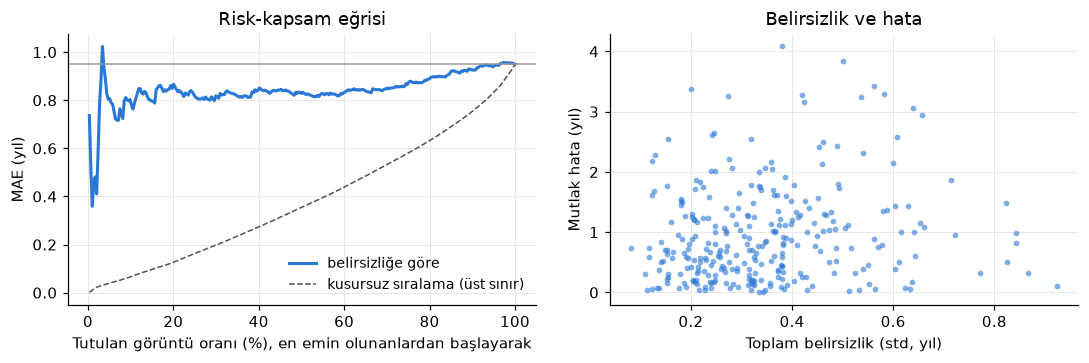

En emin %80 görüntüde MAE: 0.888
En emin %50 görüntüde MAE: 0.828


In [10]:
XAI = Path('results_v2/xai/convnext_square.npz')
if XAI.exists():
    npz = np.load(XAI, allow_pickle=True); U = A.uncertainty_table(npz, bands)
    for c in ['sd_model', 'sd_tta', 'sd_total']:
        r = stats.spearmanr(U[c], U.err); print(f'{c}: ortalama {U[c].mean():.3f} yıl | hata ile Spearman ρ = {r.statistic:.2f} (p={r.pvalue:.1e})')
    print(f'Topluluk + çoğaltma tahmininin MAE\'si: {U.err.mean():.3f}')
    display(U.groupby('band', observed=True)[['err', 'sd_model', 'sd_tta', 'sd_total']].mean().reindex(A.BANDS).round(3))
    o = np.argsort(U.sd_total.values); cov = np.arange(1, len(o)+1) / len(o); risk = np.cumsum(U.err.values[o]) / np.arange(1, len(o)+1)
    orr = np.cumsum(np.sort(U.err.values)) / np.arange(1, len(o)+1)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
    ax[0].plot(cov*100, risk, color='#2a78d6', lw=2, label='belirsizliğe göre')
    ax[0].plot(cov*100, orr, color='#52514e', lw=1, ls='--', label='kusursuz sıralama (üst sınır)')
    ax[0].axhline(U.err.mean(), color='#9a9992', lw=1); ax[0].legend(frameon=False, fontsize=9)
    ax[0].set(xlabel='Tutulan görüntü oranı (%), en emin olunanlardan başlayarak', ylabel='MAE (yıl)', title='Risk-kapsam eğrisi')
    ax[1].scatter(U.sd_total, U.err, s=14, color='#2a78d6', alpha=.6, linewidths=0)
    ax[1].set(xlabel='Toplam belirsizlik (std, yıl)', ylabel='Mutlak hata (yıl)', title='Belirsizlik ve hata')
    plt.tight_layout(); plt.show()
    for k in [.8, .5]:
        n = int(len(o)*k); print(f'En emin %{int(k*100)} görüntüde MAE: {risk[n-1]:.3f}')
else:
    print('Belirsizlik sonuçları henüz üretilmedi: scripts/xai.py')

## 11. Belirsizliğin anatomik kaynağı: Grad-CAM ve belirsizlik haritaları

Grad-CAM, modelin tahmininin görüntünün hangi bölgelerine duyarlı olduğunu gösterir. ConvNeXt'in üçüncü aşamasının çıktısı (14×14) kullanılmıştır. Her görüntü için iki harita hesaplanmıştır:

- Atıf haritası: üç modelin pozitif Grad-CAM haritalarının ortalaması.
- Belirsizlik haritası: model belirsizliğinin (üç modelin tahminleri arasındaki varyans) her modelin öznitelik haritasına göre gradyanından elde edilen Grad-CAM haritası. Varyansın bir modelin haritasına göre türevi, o modelin ortalamadan sapması ile kendi tahmin gradyanının çarpımıdır. Harita, modellerin anlaşmazlığını en çok artıran bölgeleri gösterir.

Haritalar CPU'da hesaplanmıştır: Apple MPS üzerinde bu modelin gradyanları bozuk çıkmıştır (aynı görüntülerde haritaların yalnızca %4'ü pozitif, CPU'da %48), tahminler ise GPU'da doğrudur. Böylece belirsizlik ve atıf aynı uzamda temsil edilir. Haritalar, panoramik görüntünün kaba bir bölümlemesiyle özetlenmiştir: yirmilik bölgesi, büyük azılar, ön dişler ve küçük azılar, diş dışı alanlar. Bu bölümleme sabit dikdörtgenlerdir, diş segmentasyonu değildir; panoramik çekimlerdeki konum farklılıkları nedeniyle yaklaşık sonuç verir.

In [11]:
if XAI.exists():
    attr, unc = A.xai_maps(npz); masks = A.region_masks()
    area = pd.Series({k: m.mean() for k, m in masks.items()})
    Sa = A.region_shares(attr, masks); Su = A.region_shares(unc, masks)
    tab = pd.DataFrame({'Alan payı': area, 'Atıf payı': Sa.mean(), 'Belirsizlik payı': Su.mean()})
    tab['Atıf / alan'] = tab['Atıf payı'] / tab['Alan payı']; tab['Belirsizlik / alan'] = tab['Belirsizlik payı'] / tab['Alan payı']
    display(tab.round(3))
    print('Yaş bandına göre belirsizlik payı:'); display(Su.groupby(bands, observed=True).mean().reindex(A.BANDS).round(3))
    print('Yaş bandına göre atıf payı:'); display(Sa.groupby(bands, observed=True).mean().reindex(A.BANDS).round(3))

,Alan payı,Atıf payı,Belirsizlik payı,Atıf / alan,Belirsizlik / alan
Yirmilik bölgesi,0.118,0.123,0.132,1.046,1.125
Büyük azılar,0.123,0.204,0.145,1.661,1.180
"Ön dişler, küçük azılar",0.118,0.163,0.115,1.383,0.976
"Diş dışı (kemik, kafatası)",0.642,0.510,0.608,0.795,0.947


Yaş bandına göre belirsizlik payı:


,Yirmilik bölgesi,Büyük azılar,"Ön dişler, küçük azılar","Diş dışı (kemik, kafatası)"
9-11,0.113,0.133,0.114,0.640
12-13,0.124,0.156,0.118,0.602
14-15,0.136,0.148,0.115,0.601
16,0.129,0.133,0.110,0.628
17,0.135,0.148,0.120,0.598
18-19,0.148,0.144,0.109,0.599


Yaş bandına göre atıf payı:


,Yirmilik bölgesi,Büyük azılar,"Ön dişler, küçük azılar","Diş dışı (kemik, kafatası)"
9-11,0.130,0.147,0.109,0.614
12-13,0.125,0.208,0.163,0.505
14-15,0.102,0.241,0.204,0.453
16,0.123,0.209,0.166,0.502
17,0.126,0.210,0.160,0.505
18-19,0.140,0.171,0.136,0.553


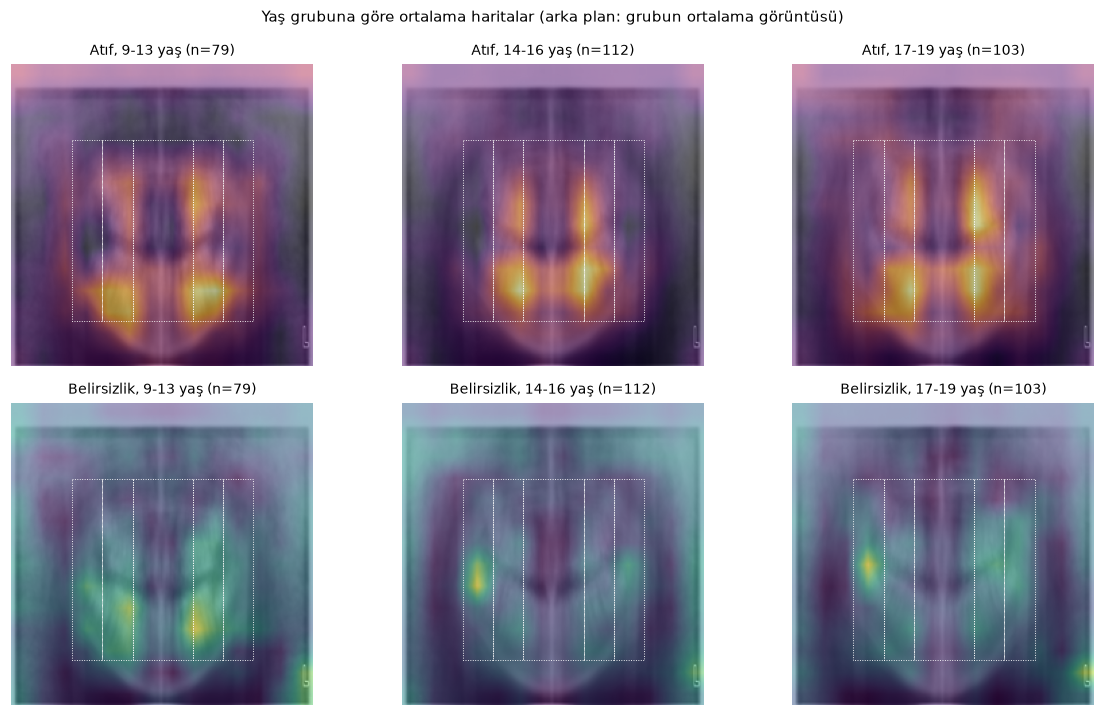

In [12]:
if XAI.exists():
    mean_img = np.stack([exp.load_image(p, 'square')[0].numpy() for p in df.path]).astype(float)
    groups = [('9-13', np.isin(bands, ['9-11', '12-13'])), ('14-16', np.isin(bands, ['14-15', '16'])), ('17-19', np.isin(bands, ['17', '18-19']))]
    fig, axes = plt.subplots(2, 3, figsize=(11, 6.6))
    for k, (g, m) in enumerate(groups):
        for row, (M, nm, cmap) in enumerate([(attr, 'Atıf', 'inferno'), (unc, 'Belirsizlik', 'viridis')]):
            ax = axes[row, k]; ax.imshow(mean_img[m].mean(0), cmap='gray')
            h = M[m].mean(0); ax.imshow(h / h.max(), cmap=cmap, alpha=.5); ax.axis('off')
            ax.set_title(f'{nm}, {g} yaş (n={m.sum()})', fontsize=9)
            for (x0, x1), (y0, y1) in [b for bs in A.REGIONS.values() for b in bs]:
                ax.add_patch(plt.Rectangle((x0*224, y0*224), (x1-x0)*224, (y1-y0)*224, fill=False, ec='white', lw=.6, ls=':'))
    plt.suptitle('Yaş grubuna göre ortalama haritalar (arka plan: grubun ortalama görüntüsü)', fontsize=10)
    plt.tight_layout(); plt.show()

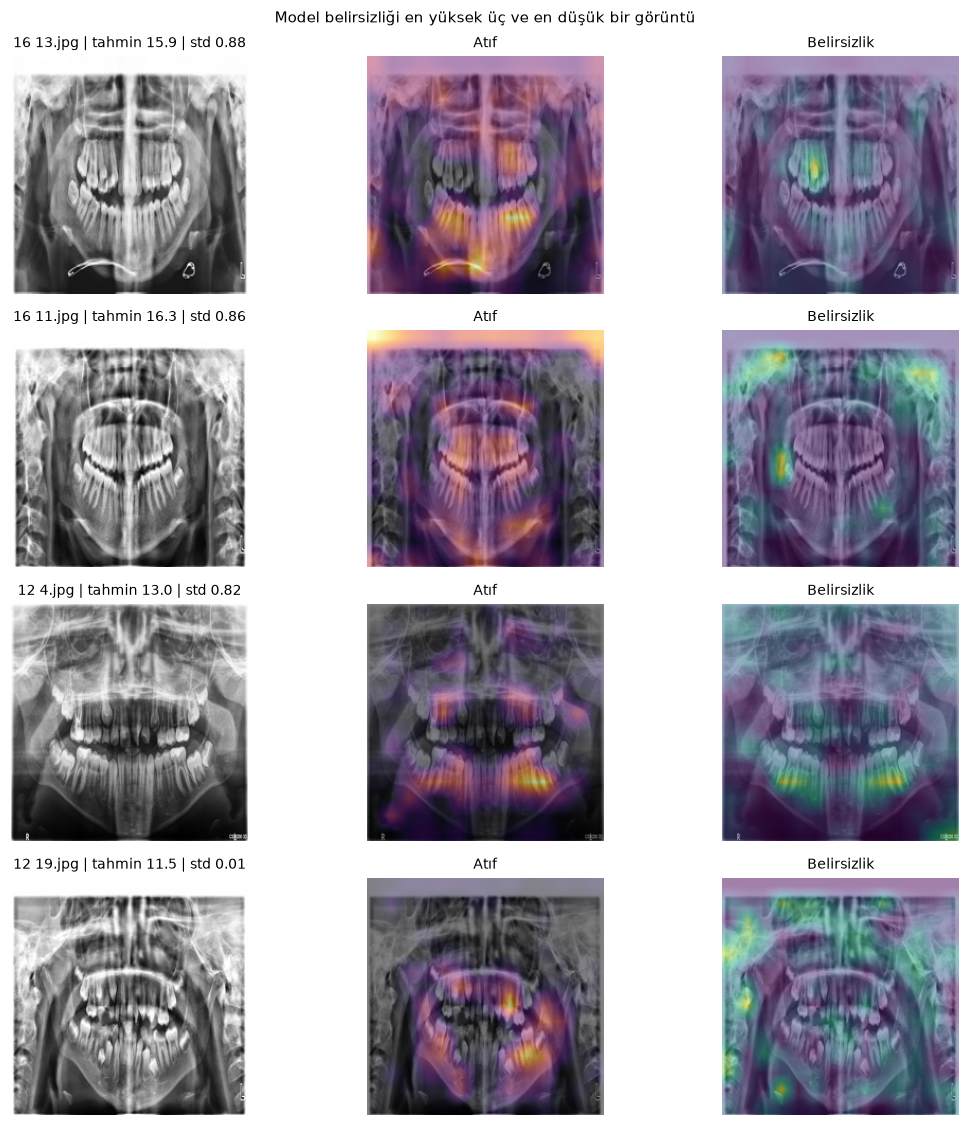

In [13]:
if XAI.exists():
    pick = list(U.sort_values('sd_model', ascending=False).index[:3]) + list(U.sort_values('sd_model').index[:1])
    fig, axes = plt.subplots(len(pick), 3, figsize=(10.5, 2.6*len(pick)))
    for r, i in enumerate(pick):
        img = exp.load_image(df.path[i], 'square')[0].numpy()
        axes[r,0].imshow(img, cmap='gray'); axes[r,0].set_title(f'{df.name[i]} | tahmin {U.pred[i]:.1f} | std {U.sd_model[i]:.2f}', fontsize=9)
        axes[r,1].imshow(img, cmap='gray'); axes[r,1].imshow(attr[i]/attr[i].max(), cmap='inferno', alpha=.5); axes[r,1].set_title('Atıf', fontsize=9)
        axes[r,2].imshow(img, cmap='gray'); axes[r,2].imshow(unc[i]/(unc[i].max()+1e-9), cmap='viridis', alpha=.5); axes[r,2].set_title('Belirsizlik', fontsize=9)
        for a in axes[r]: a.axis('off')
    plt.suptitle('Model belirsizliği en yüksek üç ve en düşük bir görüntü', fontsize=10); plt.tight_layout(); plt.show()

## 12. Adli öznitelik: yirmilik diş gelişim evresi

Projede Cameriere açık apeks oranı, Kvaal genişlik oranları ve pulpa-diş alan oranı gibi adli ölçütlerin derin öznitelik vektörüne eklenmesi planlanmaktadır. Bu ölçütler diş sınırlarının ve kök uçlarının işaretlenmesini gerektirir. Bu veride görüntülerin çoğu 400 piksel genişliğinde olduğundan kök ucu açıklığının ve pulpa sınırının milimetrik ölçümü güvenilir biçimde yapılamamaktadır. Ön çalışmada bu nedenle, düşük çözünürlükte de değerlendirilebilen ve adli literatürde yerleşik bir ölçüt kullanılmıştır: alt çene yirmilik dişlerinin (38 ve 48) gelişim evresi.

Evreleme, Demirjian evrelerinin kaba bir gruplamasıyla yapılmıştır: 0 diş veya kese görünmüyor, 1 kese ya da kron oluşuyor (A-C), 2 kron tamamlanmış (D), 3 kök oluşuyor (E-F), 4 kök boyu tamamlanmış, apeks açık (G). Apeks kapanması (H) bu çözünürlükte güvenilir biçimde ayırt edilemediğinden kullanılmamıştır.

Evreleme kör yapılmıştır: görüntüler yaş bilgisi gizlenerek rastgele kimliklerle gösterilmiş, kimlik-dosya eşlemesi evreleme bitene kadar açılmamıştır. Evrelemeyi yapay zeka asistanı (Claude) gerçekleştirmiştir; uzman doğrulaması yoktur ve tek değerlendirici vardır. Değerlendirici içi tutarlılık için sağ-sol uyumu raporlanmıştır.

Öznitelik modele iki şekilde katılmıştır: yalnızca evre ile doğrusal regresyon (adli ölçütün tek başına başarımı) ve ConvNeXt'in havuzlanmış öznitelik vektörüne iki evre değerinin eklenip son katmanın birlikte eğitilmesi.

In [14]:
st = pd.read_csv('annot/pass1.csv', dtype=str).merge(pd.read_csv('annot/key.csv', dtype={'id': str}), on='id')
for c in ['r48', 'r38']: st[c] = pd.to_numeric(st[c], errors='coerce')
st['age'] = st.name.str.extract(r'^(\d+)')[0].astype(int)
both = st.dropna(subset=['r48', 'r38'])
print(f'Değerlendirilemeyen taraf: {int(st[["r48","r38"]].isna().sum().sum())} | sağ-sol aynı evre: %{(both.r48==both.r38).mean()*100:.1f} | '
      f'en fazla 1 evre fark: %{((both.r48-both.r38).abs()<=1).mean()*100:.1f}')
sv = st[['r48', 'r38']].mean(axis=1)
r = stats.spearmanr(sv, st.age, nan_policy='omit'); print(f'Ortalama evre ile yaş: Spearman ρ = {r.statistic:.2f}')
display(pd.crosstab(st.age, st[['r48', 'r38']].max(axis=1).astype('Int64'), rownames=['Yaş'], colnames=['Evre (iki taraftan büyük olan)']))

Değerlendirilemeyen taraf: 5 | sağ-sol aynı evre: %92.1 | en fazla 1 evre fark: %98.6
Ortalama evre ile yaş: Spearman ρ = 0.73


Evre (iki taraftan büyük olan),0,1,2,3,4
Yaş,,,,,
9,4,1,0,0,0
10,0,3,0,0,0
11,3,12,2,0,0
12,10,22,2,2,0
13,1,8,8,1,0
14,0,10,31,1,0
15,0,2,17,1,0
16,0,6,36,8,0
17,0,1,31,23,1


In [15]:
rows = []
ref = RUNS.get('ConvNeXt-Tiny')
if ref:
    for lab, P in [('Taban çizgisi (ortanca)', A.median_baseline(df, ref)), ('Yalnızca yirmilik evresi (doğrusal)', A.stage_baseline(df, ref)),
                   ('Yalnızca ConvNeXt', A.oof(ref, len(df)))] + ([('ConvNeXt + yirmilik evresi', A.oof(RUNS['ConvNeXt + yirmilik evresi'], len(df)))] if 'ConvNeXt + yirmilik evresi' in RUNS else []):
        rep_mae = [np.abs(p - y).mean() for p in P]
        rows.append({'Model': lab, 'MAE ort.': np.mean(rep_mae), 'MAE std': np.std(rep_mae, ddof=1) if len(P) > 1 else np.nan,
                     **{f'{b}': v for b, v in A.band_mae(P, y, bands).items()}})
    abl = pd.DataFrame(rows); display(abl.round(3))
    if 'ConvNeXt + yirmilik evresi' in RUNS:
        a0 = np.abs(A.oof(ref, len(df)) - y).mean(0); a1 = np.abs(A.oof(RUNS['ConvNeXt + yirmilik evresi'], len(df)) - y).mean(0)
        d = a1 - a0; rng = np.random.default_rng(42); bs = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(5000)]
        print(f'Öznitelik eklemenin MAE farkı: {d.mean():+.3f} yıl (%95 GA {np.percentile(bs, 2.5):+.3f} / {np.percentile(bs, 97.5):+.3f}), '
              f'Wilcoxon p = {stats.wilcoxon(a1, a0).pvalue:.4f}')

,Model,MAE ort.,MAE std,9-11,12-13,14-15,16,17,18-19
0,Taban çizgisi (ortanca),2.041,0.000,5.520,3.667,1.677,0.000,1.000,2.213
1,Yalnızca yirmilik evresi (doğrusal),1.345,0.006,2.351,1.464,0.937,1.096,1.265,1.572
2,Yalnızca ConvNeXt,0.991,0.016,1.124,0.859,1.008,0.893,0.773,1.416
3,ConvNeXt + yirmilik evresi,0.999,0.026,1.036,0.880,0.953,0.886,0.833,1.496


Öznitelik eklemenin MAE farkı: +0.008 yıl (%95 GA -0.025 / +0.041), Wilcoxon p = 0.7884


## 13. Küçük örneklem için düzenlileştirme: ikili sıralama ve sol-sağ simetri

- İkili sıralama kaybı: her toplu işlemdeki görüntü çiftlerinde, yaşı büyük olanın tahmininin de büyük olması istenir (RankNet biçiminde lojistik kayıp, ağırlık 0,5). Yaşın mutlak değerine ek olarak göreli sırasını öğretir ve ortalamaya çekmeyi azaltması beklenir.
- Sol-sağ simetri tutarlılığı: görüntü ve yatay aynası aynı yaşı vermelidir. Ayna görüntüsünün tahmini ile özgün görüntünün tahmini arasındaki mutlak farka ağırlık 1 ile ceza uygulanır. Bu, bir tarafa özgü ezberlemeyi sınırlar.

İki yöntemin ağırlıkları önceden sabitlenmiştir ve ayarlanmamıştır.

In [16]:
rows = []
for lab in ['ConvNeXt-Tiny', 'ConvNeXt + sıralama', 'ConvNeXt + simetri', 'ConvNeXt dolgulu', 'ConvNeXt + yirmilik evresi']:
    if lab not in RUNS: continue
    P = A.oof(RUNS[lab], len(df)); s = A.summarize(P, y, RUNS[lab]); m = A.metrics(y, P.mean(0))
    rows.append({'Deney': lab, 'Tekrar': s['reps'], 'MAE ort.': s['MAE_mean'], 'MAE std': s['MAE_sd'], 'Topluluk MAE': s['MAE_ensemble'],
                 'Eğim': m['slope'], '18-19 MAE': A.band_mae(P, y, bands)['18-19']})
pd.DataFrame(rows).round(3)

,Deney,Tekrar,MAE ort.,MAE std,Topluluk MAE,Eğim,18-19 MAE
0,ConvNeXt-Tiny,3,0.991,0.016,0.951,0.721,1.416
1,ConvNeXt dolgulu,3,0.976,0.041,0.935,0.749,1.369
2,ConvNeXt + yirmilik evresi,3,0.999,0.026,0.966,0.734,1.496


## 14. Sonuç

Sonuçlar tamamlandığında bu bölüm güncellenecektir.